In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
FILES = {
    "airfare":   "../data/CUSR0000SETG01.csv",   # target
    "jet_fuel":  "../data/DJFUELUSGULF.csv",
    "cpi":       "../data/CPIAUCSL.csv",
    "unemp":     "../data/UNRATE.csv",
    "sentiment": "../data/UMCSENT.csv",
}

def load_fred(path, name):
    df = pd.read_csv(path)
    date_col, value_col = df.columns[0], df.columns[1]
    df[date_col] = pd.to_datetime(df[date_col])
    df[value_col] = pd.to_numeric(df[value_col], errors="coerce")
    s = df.set_index(date_col)[value_col].rename(name)
    return s.resample("MS").mean()          # daily -> monthly average

series = {name: load_fred(f, name) for name, f in FILES.items()}
for name, s in series.items():
    print(f"{name:10s} {s.index.min():%b %Y} to {s.index.max():%b %Y}")

airfare    Jan 1989 to Aug 2026
jet_fuel   Apr 1990 to Sep 2026
cpi        Jan 1947 to Aug 2026
unemp      Jan 1948 to Sep 2026
sentiment  Nov 1952 to Aug 2026


In [3]:
data = pd.concat(series.values(), axis=1)
data = data.loc[data.dropna().index.min():]
data = data.interpolate(limit=3, limit_area="inside").dropna()
data.index.name = "date"

data.to_csv("../data/merged_monthly.csv")
print(f"{len(data)} months: {data.index.min():%b %Y} to {data.index.max():%b %Y}")
data.tail()

437 months: Apr 1990 to Aug 2026


,airfare,jet_fuel,cpi,unemp,sentiment
date,,,,,
2026-04-01,299.267,3.928238,332.407,4.3,49.8
2026-05-01,307.305,3.942550,333.979,4.3,44.8
2026-06-01,307.963,3.041619,332.568,4.2,49.5
2026-07-01,314.803,3.403000,332.813,4.1,55.2
2026-08-01,323.244,3.724143,334.131,4.1,51.7


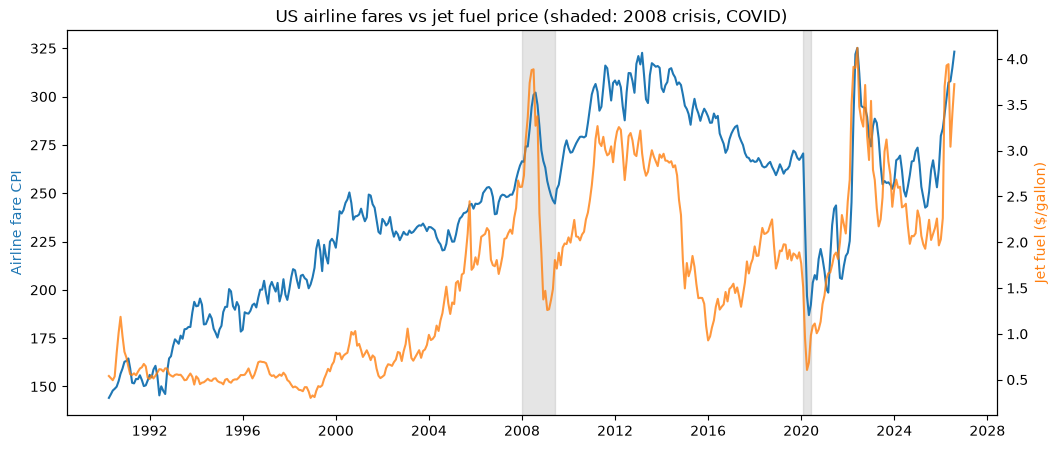

In [4]:
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(data.index, data["airfare"], color="tab:blue")
ax1.set_ylabel("Airline fare CPI", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(data.index, data["jet_fuel"], color="tab:orange", alpha=0.8)
ax2.set_ylabel("Jet fuel ($/gallon)", color="tab:orange")
for start, end in [("2008-01", "2009-06"), ("2020-02", "2020-06")]:
    ax1.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="grey", alpha=0.2)
plt.title("US airline fares vs jet fuel price (shaded: 2008 crisis, COVID)")
plt.show()

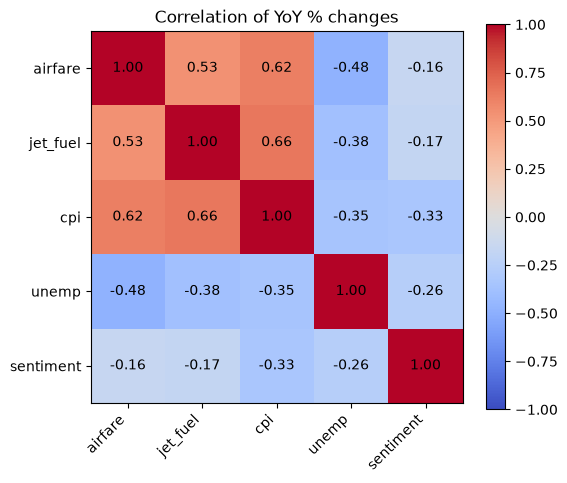

,airfare,jet_fuel,cpi,unemp,sentiment
airfare,1.00,0.53,0.62,-0.48,-0.16
jet_fuel,0.53,1.00,0.66,-0.38,-0.17
cpi,0.62,0.66,1.00,-0.35,-0.33
unemp,-0.48,-0.38,-0.35,1.00,-0.26
sentiment,-0.16,-0.17,-0.33,-0.26,1.00


In [5]:
yoy = data.pct_change(12).dropna() * 100
corr = yoy.corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im)
plt.title("Correlation of YoY % changes")
plt.show()
corr.round(2)

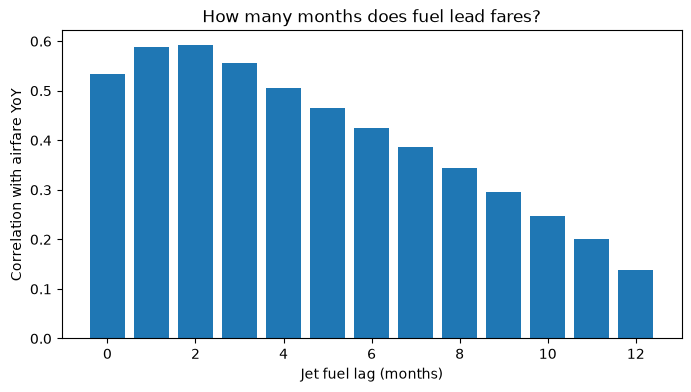

Best fuel lag: 2 months


In [6]:
lags = range(0, 13)
lag_corr = [yoy["airfare"].corr(yoy["jet_fuel"].shift(k)) for k in lags]
best_lag = max(lags, key=lambda k: lag_corr[k])

plt.figure(figsize=(8, 4))
plt.bar(lags, lag_corr)
plt.xlabel("Jet fuel lag (months)")
plt.ylabel("Correlation with airfare YoY")
plt.title("How many months does fuel lead fares?")
plt.show()
print("Best fuel lag:", best_lag, "months")

In [7]:
fuel_lag = max(1, best_lag)

df = pd.DataFrame(index=data.index)
df["y"]         = np.log(data["airfare"])
df["fuel"]      = np.log(data["jet_fuel"]).shift(fuel_lag)
df["cpi"]       = np.log(data["cpi"]).shift(1)
df["unemp"]     = data["unemp"].shift(1)
df["sentiment"] = data["sentiment"].shift(1)
df["covid"]     = ((df.index >= "2020-03-01") & (df.index <= "2021-06-01")).astype(int)

df = df.dropna().asfreq("MS")
features = ["fuel", "cpi", "unemp", "sentiment", "covid"]
print("Fuel lag used:", fuel_lag, "| rows:", len(df))
df.head()

Fuel lag used: 2 | rows: 435


,y,fuel,cpi,unemp,sentiment,covid
date,,,,,,
1990-06-01,4.996536,-0.616495,4.860587,5.4,90.6,0
1990-07-01,5.002603,-0.660833,4.866765,5.2,88.3,0
1990-08-01,5.009968,-0.705220,4.871373,5.5,88.2,0
1990-09-01,5.029130,-0.625769,4.879767,5.7,76.4,0
1990-10-01,5.053695,-0.235147,4.886583,5.9,72.8,0


In [8]:
#Train test and split

In [9]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score

test_start = df.index[-36]
train = df[df.index < test_start]
test  = df[df.index >= test_start]
actual = data["airfare"].loc[test.index]

print(f"Train: {train.index.min():%b %Y} to {train.index.max():%b %Y} ({len(train)} months)")
print(f"Test:  {test.index.min():%b %Y} to {test.index.max():%b %Y} ({len(test)} months)")

results = {}
def evaluate(name, pred):
    results[name] = {
        "MAPE %": mean_absolute_percentage_error(actual, pred) * 100,
        "RMSE":   np.sqrt(mean_squared_error(actual, pred)),
        "R²":     r2_score(actual, pred),
    }
    return pd.DataFrame(results).T.round(3)

Train: Jun 1990 to Aug 2023 (399 months)
Test:  Sep 2023 to Aug 2026 (36 months)


In [10]:
#Naive baselin

In [11]:
naive = data["airfare"].shift(1).loc[test.index]
evaluate("Naive (last month)", naive)

,MAPE %,RMSE,R²
Naive (last month),2.152,6.958,0.882


In [12]:
#Model 1: linear regression (macro indicators only)

In [13]:
import statsmodels.api as sm

# Model 1: ordinary least squares on the same lagged macro features, without fare history
X_train = sm.add_constant(train[features])
X_test  = sm.add_constant(test[features], has_constant="add")
res_ols = sm.OLS(train["y"], X_train).fit()
pred_ols = np.exp(res_ols.predict(X_test))

print(pd.DataFrame({"coefficient": res_ols.params,
                    "p_value":     res_ols.pvalues}).round(4))
print()
evaluate("Linear regression (macro only)", pred_ols)

           coefficient  p_value
const           1.9025      0.0
fuel            0.1344      0.0
cpi             0.5643      0.0
unemp           0.0250      0.0
sentiment       0.0049      0.0
covid          -0.3000      0.0



,MAPE %,RMSE,R²
Naive (last month),2.152,6.958,0.882
Linear regression (macro only),11.729,33.686,-1.771


In [14]:
#ARIMAX model, plus ARIMA without macro for comparison

In [15]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

def arima_forecast(exog_cols, order=(1, 1, 1)):
    ex_train = train[exog_cols] if exog_cols else None
    ex_all   = df[exog_cols] if exog_cols else None
    res  = SARIMAX(train["y"], exog=ex_train, order=order).fit(disp=False, maxiter=1000)
    print("Converged:", res.mle_retvals["converged"])
    full = SARIMAX(df["y"], exog=ex_all, order=order).filter(res.params)
    pred = full.get_prediction(start=test.index[0]).predicted_mean
    return np.exp(pred), res

pred_arima,  res_arima  = arima_forecast([])
pred_arimax, res_arimax = arima_forecast(features)

evaluate("ARIMA (no macro)", pred_arima)
evaluate("ARIMAX (with macro)", pred_arimax)

Converged: True
Converged: True


,MAPE %,RMSE,R²
Naive (last month),2.152,6.958,0.882
Linear regression (macro only),11.729,33.686,-1.771
ARIMA (no macro),1.849,5.777,0.919
ARIMAX (with macro),1.771,5.623,0.923


In [16]:
pd.DataFrame({"coefficient": res_arimax.params,
              "p_value":     res_arimax.pvalues}).round(4)

,coefficient,p_value
fuel,0.0126,0.3272
cpi,1.6723,0.0000
unemp,0.0007,0.7500
sentiment,0.0002,0.2787
covid,-0.0457,0.0000
ar.L1,-0.1269,0.0702
ma.L1,0.6714,0.0000
sigma2,0.0005,0.0000


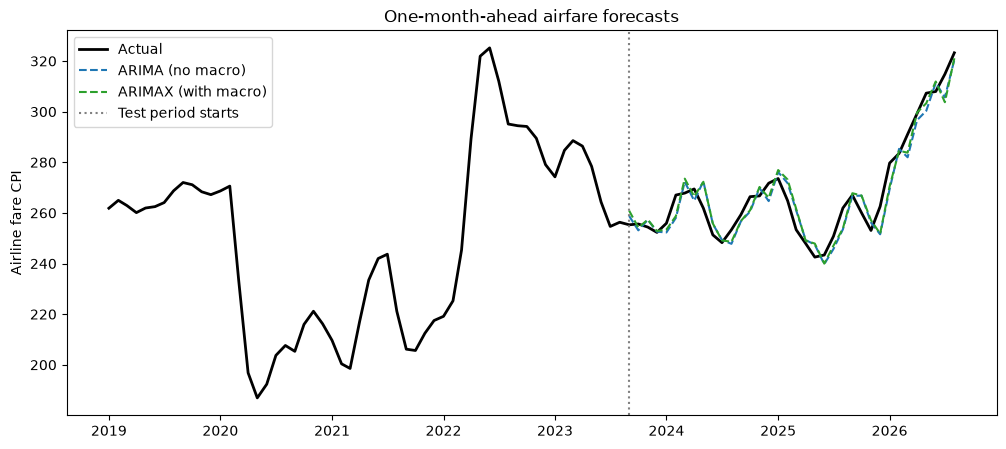

In [17]:
plt.figure(figsize=(12, 5))
plt.plot(data["airfare"].loc["2019":], color="black", linewidth=2, label="Actual")
plt.plot(pred_arima,  "--", color="tab:blue",  label="ARIMA (no macro)")
plt.plot(pred_arimax, "--", color="tab:green", label="ARIMAX (with macro)")
plt.axvline(test_start, color="grey", linestyle=":", label="Test period starts")
plt.title("One-month-ahead airfare forecasts")
plt.ylabel("Airline fare CPI")
plt.legend()
plt.show()

In [18]:
pd.DataFrame(results).T.round(3).sort_values("MAPE %")

,MAPE %,RMSE,R²
ARIMAX (with macro),1.771,5.623,0.923
ARIMA (no macro),1.849,5.777,0.919
Naive (last month),2.152,6.958,0.882
Linear regression (macro only),11.729,33.686,-1.771


In [19]:
import itertools

search = []
for p, q in itertools.product(range(0, 4), range(0, 4)):
    try:
        r = SARIMAX(train["y"], exog=train[features], order=(p, 1, q)).fit(disp=False, maxiter=1000)
        search.append({"order": (p, 1, q), "AIC": r.aic})
    except Exception:
        pass

search = pd.DataFrame(search).sort_values("AIC")
best_order = search.iloc[0]["order"]
print("Best order by AIC:", best_order)
print(search.head())

pred_tuned, res_tuned = arima_forecast(features, order=best_order)
evaluate(f"ARIMAX tuned {best_order}", pred_tuned)

Best order by AIC: (1, 1, 2)
        order          AIC
6   (1, 1, 2) -1873.920980
10  (2, 1, 2) -1873.168264
7   (1, 1, 3) -1871.674879
14  (3, 1, 2) -1870.700538
11  (2, 1, 3) -1870.329145
Converged: True


,MAPE %,RMSE,R²
Naive (last month),2.152,6.958,0.882
Linear regression (macro only),11.729,33.686,-1.771
ARIMA (no macro),1.849,5.777,0.919
ARIMAX (with macro),1.771,5.623,0.923
"ARIMAX tuned (1, 1, 2)",1.782,5.712,0.920


In [20]:
def walk_forward(exog_cols, order):
    preds = []
    for t in test.index:
        hist = df[df.index < t]                                   # all data before month t
        r = SARIMAX(hist["y"], exog=hist[exog_cols] if exog_cols else None,
                    order=order).fit(disp=False, maxiter=1000)
        fc = r.forecast(steps=1, exog=df.loc[[t], exog_cols] if exog_cols else None)
        preds.append(np.exp(fc.iloc[0]))
    return pd.Series(preds, index=test.index)

pred_wf_arima  = walk_forward([], best_order)          # no macro, for fair comparison
pred_wf_arimax = walk_forward(features, best_order)    # with macro

evaluate("ARIMA walk-forward (no macro)", pred_wf_arima)
evaluate("ARIMAX walk-forward (with macro)", pred_wf_arimax)

C:\Users\Thirumaleswari\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,MAPE %,RMSE,R²
Naive (last month),2.152,6.958,0.882
Linear regression (macro only),11.729,33.686,-1.771
ARIMA (no macro),1.849,5.777,0.919
ARIMAX (with macro),1.771,5.623,0.923
"ARIMAX tuned (1, 1, 2)",1.782,5.712,0.920
ARIMA walk-forward (no macro),1.848,5.837,0.917
ARIMAX walk-forward (with macro),1.805,5.749,0.919


In [21]:
pred_ensemble = (pred_wf_arimax + pred_wf_arima + naive) / 3
evaluate("Ensemble (avg of 3)", pred_ensemble)

,MAPE %,RMSE,R²
Naive (last month),2.152,6.958,0.882
Linear regression (macro only),11.729,33.686,-1.771
ARIMA (no macro),1.849,5.777,0.919
ARIMAX (with macro),1.771,5.623,0.923
"ARIMAX tuned (1, 1, 2)",1.782,5.712,0.920
ARIMA walk-forward (no macro),1.848,5.837,0.917
ARIMAX walk-forward (with macro),1.805,5.749,0.919
Ensemble (avg of 3),1.888,5.955,0.913


In [22]:
final = pd.DataFrame(results).T.round(3).sort_values("MAPE %")
final

,MAPE %,RMSE,R²
ARIMAX (with macro),1.771,5.623,0.923
"ARIMAX tuned (1, 1, 2)",1.782,5.712,0.920
ARIMAX walk-forward (with macro),1.805,5.749,0.919
ARIMA walk-forward (no macro),1.848,5.837,0.917
ARIMA (no macro),1.849,5.777,0.919
Ensemble (avg of 3),1.888,5.955,0.913
Naive (last month),2.152,6.958,0.882
Linear regression (macro only),11.729,33.686,-1.771


In [23]:
from sklearn.metrics import mean_absolute_percentage_error

def make_features(h):
    """Build features where every macro variable is known h months in advance."""
    d = pd.DataFrame(index=data.index)
    d["y"]         = np.log(data["airfare"])
    d["fuel"]      = np.log(data["jet_fuel"]).shift(max(fuel_lag, h))
    d["cpi"]       = np.log(data["cpi"]).shift(max(1, h))
    d["unemp"]     = data["unemp"].shift(max(1, h))
    d["sentiment"] = data["sentiment"].shift(max(1, h))
    d["covid"]     = ((d.index >= "2020-03-01") & (d.index <= "2021-06-01")).astype(int)
    return d.dropna().asfreq("MS")

def h_step_forecast(d, exog_cols, h, order=(1, 1, 1)):
    """Forecast each test month from an origin h months earlier."""
    ex = lambda x: x[exog_cols] if exog_cols else None
    tr = d[d.index < test_start]
    res = SARIMAX(tr["y"], exog=ex(tr), order=order).fit(disp=False, maxiter=1000)  # learn on train only

    preds = {}
    for target in d.index[d.index >= test_start]:
        origin = d.index.get_loc(target) - h
        hist = d.iloc[:origin + 1]                    # data known at the forecast origin
        fut  = d.iloc[origin + 1: origin + 1 + h]     # exog for the next h months (lagged, so known)
        m = SARIMAX(hist["y"], exog=ex(hist), order=order).filter(res.params)
        preds[target] = np.exp(m.forecast(steps=h, exog=ex(fut)).iloc[-1])
    return pd.Series(preds)

In [24]:
horizons = [1, 3, 6, 12]
rows = []

for h in horizons:
    d = make_features(h)
    targets = d.index[d.index >= test_start]
    act = data["airfare"].loc[targets]

    naive_h  = data["airfare"].shift(h).loc[targets]       # forecast = value h months ago
    arima_h  = h_step_forecast(d, [], h)
    arimax_h = h_step_forecast(d, features, h)

    m_naive  = mean_absolute_percentage_error(act, naive_h) * 100
    m_arima  = mean_absolute_percentage_error(act, arima_h) * 100
    m_arimax = mean_absolute_percentage_error(act, arimax_h) * 100

    rows.append({"Horizon (months)": h,
                 "Naive MAPE %": m_naive,
                 "ARIMA MAPE %": m_arima,
                 "ARIMAX MAPE %": m_arimax,
                 "Macro gain %": (m_arima - m_arimax) / m_arima * 100})
    print(f"Horizon {h} done")

horizon_table = pd.DataFrame(rows).set_index("Horizon (months)").round(2)
horizon_table

Horizon 1 done
Horizon 3 done
Horizon 6 done
Horizon 12 done


,Naive MAPE %,ARIMA MAPE %,ARIMAX MAPE %,Macro gain %
Horizon (months),,,,
1,2.15,1.85,1.77,4.23
3,4.97,4.71,4.72,-0.28
6,6.96,6.96,6.78,2.64
12,7.97,7.88,7.65,2.94


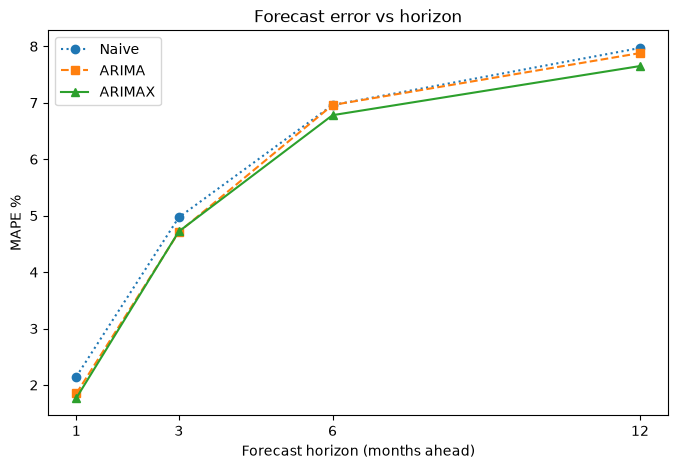

In [25]:
plt.figure(figsize=(8, 5))
for col, style in [("Naive MAPE %", "o:"), ("ARIMA MAPE %", "s--"), ("ARIMAX MAPE %", "^-")]:
    plt.plot(horizon_table.index, horizon_table[col], style, label=col.replace(" MAPE %", ""))
plt.xlabel("Forecast horizon (months ahead)")
plt.ylabel("MAPE %")
plt.title("Forecast error vs horizon")
plt.xticks(horizons)
plt.legend()
plt.show()